# Do the vectors recognize emotions in stories they never saw? (CPU)

A proof test on Praveen's held-out stories (validation topics 14–16 and test topics 17–19, 336 stories, 24 per emotion). None of them were used to build the vectors.

For each held-out story and each block: subtract the training center, measure how far the story points along each of the 14 emotion vectors, and guess the emotion with the largest score. Chance is 1 in 14 = 7.1%.

This answers two questions with data:
1. **Do the vectors mean what their labels say?** If they do, the guess should be right far more often than 7.1%.
2. **Which layer?** Accuracy at every block shows where the emotion is clearest, next to the "two-thirds of the way in" rule (block 23 of 36, block 18 of 28).

Needs `story_activations.npz` and `emotion_vectors.npz` for the 8B run (Drive archive) and, if present, the 0.6B ones from `qwen0p6b.ipynb`. Outputs go to `results/probe/`.

In [1]:
import csv, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))
from src.extract import probe_accuracy, projections

OUT = Path("../results/probe")
OUT.mkdir(parents=True, exist_ok=True)
RUNS = {
    "Qwen3-8B": (Path("../emotion_vector_pipeline/outputs/emotion_extraction/ab1333f49024705c"), 23),
    "Qwen3-0.6B": (Path("../emotion_vector_pipeline/outputs/emotion_extraction_qwen3_0p6b"), 18),
}

def load(run_dir):
    with np.load(run_dir / "emotion_vectors.npz", allow_pickle=False) as v:
        names, unit, center = v["emotion_names"].tolist(), v["unit_vectors"], v["center"]
    with np.load(run_dir / "story_activations.npz", allow_pickle=False) as a:
        keep = np.isin(a["splits"], ["validation", "test"])  #held-out stories only
        acts, emotions, splits = a["pooled"][keep], a["emotions"][keep], a["splits"][keep]
    return names, unit, center, acts, emotions, splits

## 1. Accuracy at every block

In [2]:
results = {}
for model_name, (run_dir, chosen) in RUNS.items():
    if not (run_dir / "story_activations.npz").exists():
        print("skipping", model_name, "(no activations found)")
        continue
    names, unit, center, acts, emotions, splits = load(run_dir)
    labels = np.array([names.index(e) for e in emotions])
    acc = {s: probe_accuracy(acts[splits == s], labels[splits == s], unit, center) for s in ["validation", "test"]}
    acc["held-out"] = probe_accuracy(acts, labels, unit, center)
    results[model_name] = dict(chosen=chosen, n_blocks=unit.shape[1], acc=acc, names=names,
                               acts=acts, labels=labels, unit=unit, center=center)
    best = int(acc["validation"].argmax())
    print(f"{model_name}: {len(labels)} held-out stories | block {chosen}: validation {acc['validation'][chosen]:.1%}, "
          f"test {acc['test'][chosen]:.1%} | best validation block {best}: {acc['validation'][best]:.1%}")

with (OUT / "layer_accuracy.csv").open("w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["model", "block", "depth_pct", "validation", "test", "held_out"])
    for model_name, r in results.items():
        for b in range(r["n_blocks"]):
            w.writerow([model_name, b, round(100 * (b + 1) / r["n_blocks"], 1),
                        *(round(float(r["acc"][s][b]), 4) for s in ["validation", "test", "held-out"])])

Qwen3-8B: 336 held-out stories | block 23: validation 29.2%, test 23.2% | best validation block 21: 32.1%


Qwen3-0.6B: 336 held-out stories | block 18: validation 25.6%, test 21.4% | best validation block 10: 25.6%


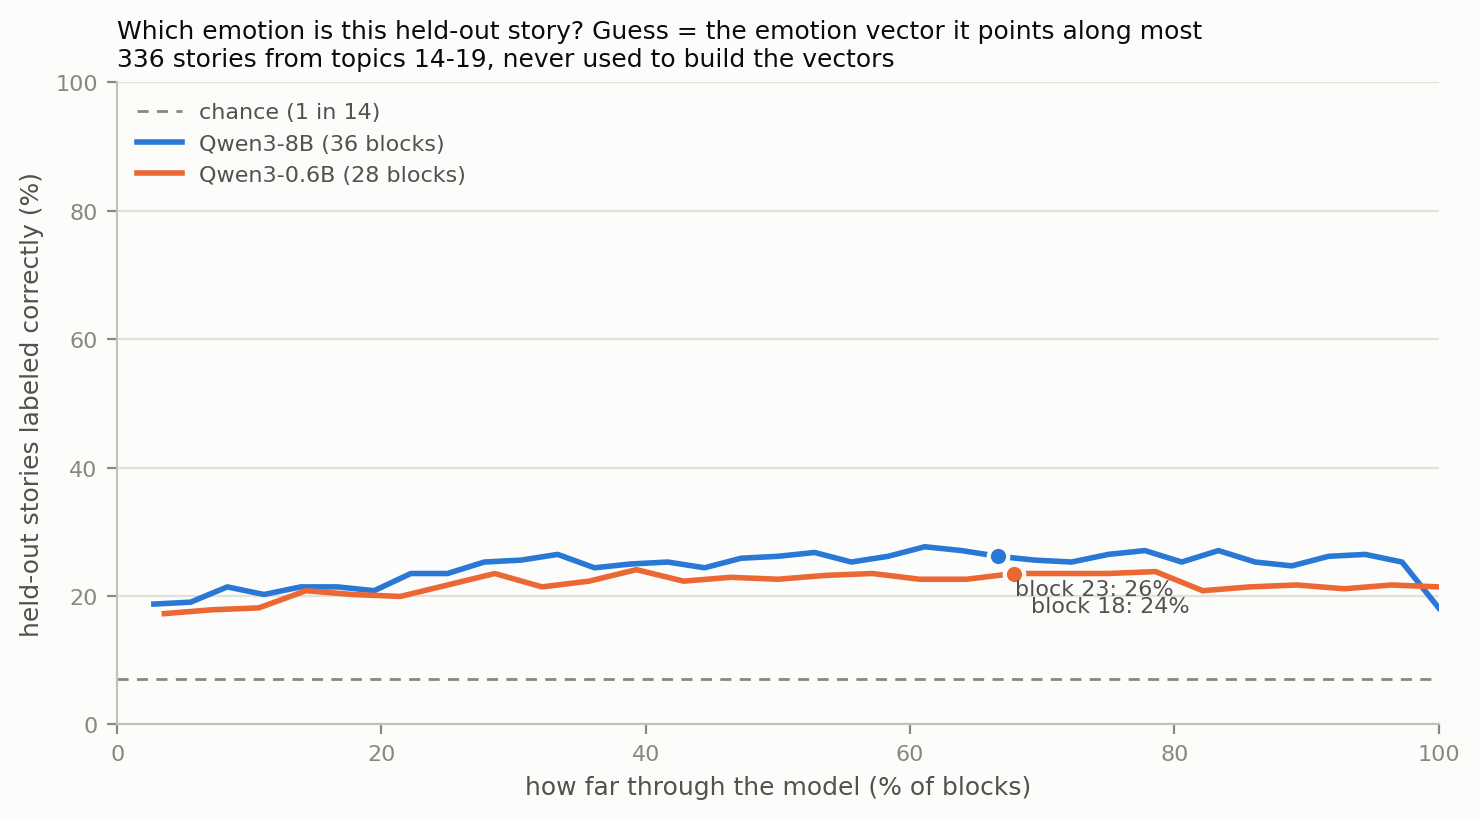

In [3]:
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
COLORS = {"Qwen3-8B": "#2a78d6", "Qwen3-0.6B": "#eb6834"}  #validated pair

fig, ax = plt.subplots(figsize=(7.5, 4.2), dpi=200)
fig.patch.set_facecolor(SURFACE); ax.set_facecolor(SURFACE)
ax.axhline(100 / 14, color=MUTED, lw=1, ls=(0, (4, 3)), label="chance (1 in 14)")
for model_name, r in results.items():
    depth = 100 * (np.arange(r["n_blocks"]) + 1) / r["n_blocks"]
    y = 100 * r["acc"]["held-out"]
    ax.plot(depth, y, color=COLORS[model_name], lw=2, label=f"{model_name} ({r['n_blocks']} blocks)")
    b = r["chosen"]
    ax.plot([depth[b]], [y[b]], "o", color=COLORS[model_name], ms=7, mec=SURFACE, mew=1.5)
    above = model_name == "Qwen3-8B"  #8B label above its dot, 0.6B below, so they never overlap
    ax.annotate(f"block {b}: {y[b]:.0f}%", (depth[b], y[b]), textcoords="offset points", xytext=(-4, 9 if above else -15),
                ha="right", color=INK2, fontsize=8)
ax.set_xlim(0, 100); ax.set_ylim(0, 40)
ax.set_xlabel("how far through the model (% of blocks)", color=INK2, fontsize=9)
ax.set_ylabel("held-out stories labeled correctly (%)", color=INK2, fontsize=9)
ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
for side in ["top", "right"]: ax.spines[side].set_visible(False)
for side in ["left", "bottom"]: ax.spines[side].set_color(AXIS)
ax.tick_params(colors=MUTED, labelsize=8)
ax.legend(loc="upper left", frameon=False, fontsize=8, labelcolor=INK2)
ax.set_title("Which emotion is this held-out story? Guess = the emotion vector it points along most\n"
             "336 stories from topics 14-19, never used to build the vectors", loc="left", color=INK, fontsize=9)
fig.tight_layout(); fig.savefig(OUT / "layer_accuracy.png", facecolor=SURFACE); plt.show()

## 2. The desperate vector on held-out stories (Qwen3-8B, block 23)

highest: [('desperate', 3.8), ('guilty', 2.9), ('angry', 2.0), ('frustrated', 1.9)]
lowest: [('calm', -8.6), ('happy', -8.5), ('proud', -7.8)]


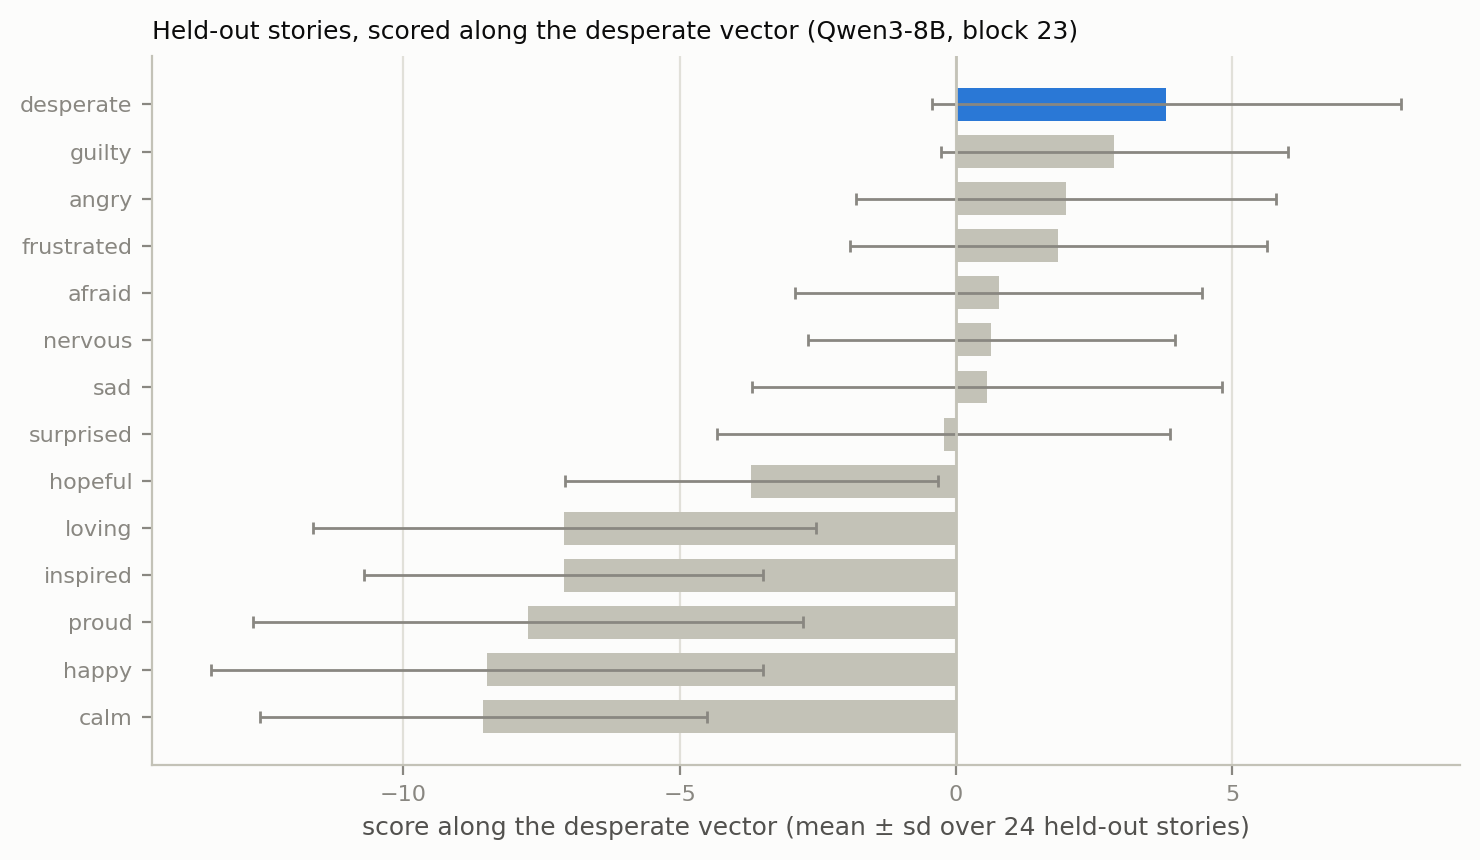

In [4]:
r = results["Qwen3-8B"]
names, b = r["names"], r["chosen"]
score = projections(r["acts"][:, b:b + 1], r["unit"][:, b:b + 1], r["center"][b:b + 1])[:, 0, names.index("desperate")]
by_emotion = {e: score[r["labels"] == i] for i, e in enumerate(names)}
order = sorted(names, key=lambda e: by_emotion[e].mean())
with (OUT / "desperate_score_by_emotion.csv").open("w", newline="") as f:
    w = csv.writer(f); w.writerow(["emotion", "n", "mean", "sd"])
    for e in order[::-1]:
        w.writerow([e, len(by_emotion[e]), round(float(by_emotion[e].mean()), 2), round(float(by_emotion[e].std()), 2)])
print("highest:", [(e, round(float(by_emotion[e].mean()), 1)) for e in order[::-1][:4]])
print("lowest:", [(e, round(float(by_emotion[e].mean()), 1)) for e in order[:3]])

fig, ax = plt.subplots(figsize=(7.5, 4.4), dpi=200)
fig.patch.set_facecolor(SURFACE); ax.set_facecolor(SURFACE)
means = [by_emotion[e].mean() for e in order]
sds = [by_emotion[e].std() for e in order]
colors = ["#2a78d6" if e == "desperate" else "#c3c2b7" for e in order]
ax.barh(order, means, xerr=sds, color=colors, height=0.7, error_kw=dict(ecolor=MUTED, lw=1, capsize=2))
ax.axvline(0, color=AXIS, lw=1)
ax.set_xlabel("score along the desperate vector (mean ± sd over 24 held-out stories)", color=INK2, fontsize=9)
ax.grid(axis="x", color=GRID, lw=0.8); ax.set_axisbelow(True)
for side in ["top", "right"]: ax.spines[side].set_visible(False)
for side in ["left", "bottom"]: ax.spines[side].set_color(AXIS)
ax.tick_params(colors=MUTED, labelsize=8)
ax.set_title("Held-out stories, scored along the desperate vector (Qwen3-8B, block 23)", loc="left", color=INK, fontsize=9)
fig.tight_layout(); fig.savefig(OUT / "desperate_score_by_emotion.png", facecolor=SURFACE); plt.show()